# Titanic – Data Preprocessing
Source: Kaggle Titanic `train.csv`. Preprocessing only, no model training.

## 1. Load data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('train.csv')
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Column types

In [2]:
col_types = pd.DataFrame({
    'column': df.columns,
    'dtype': df.dtypes.values,
    'unique': df.nunique().values,
    'type': [
        'identifier', 'binary (target)', 'ordinal', 'text / high-cardinality',
        'binary', 'numerical (continuous)', 'numerical (discrete)', 'numerical (discrete)',
        'text / high-cardinality', 'numerical (continuous)', 'text / high-cardinality (sparse)', 'nominal',
    ],
})
col_types

,column,dtype,unique,type
0,PassengerId,int64,891,identifier
1,Survived,int64,2,binary (target)
2,Pclass,int64,3,ordinal
3,Name,object,891,text / high-cardinality
4,Sex,object,2,binary
5,Age,float64,88,numerical (continuous)
6,SibSp,int64,7,numerical (discrete)
7,Parch,int64,7,numerical (discrete)
8,Ticket,object,681,text / high-cardinality
9,Fare,float64,248,numerical (continuous)


- **Numerical:** Age, SibSp, Parch, Fare
- **Nominal:** Embarked
- **Ordinal:** Pclass (1 > 2 > 3 by class)
- **Binary:** Sex, Survived
- **Text / high-cardinality:** Name, Ticket, Cabin (PassengerId is just an ID)

## 3. Missing values

In [3]:
missing = pd.DataFrame({'missing': df.isna().sum(), 'percent': (df.isna().mean() * 100).round(2)})
missing[missing.missing > 0]

,missing,percent
Age,177,19.87
Cabin,687,77.10
Embarked,2,0.22


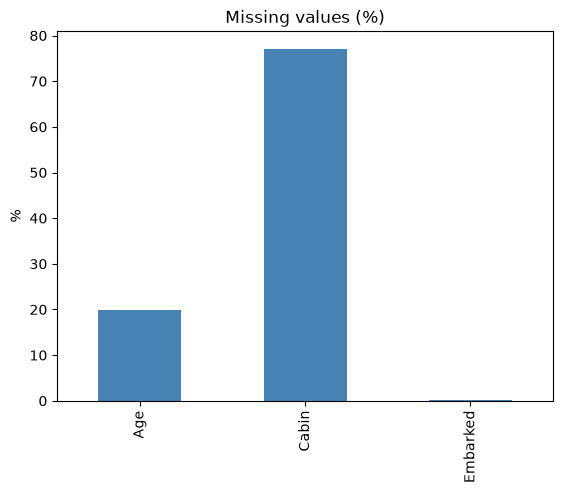

In [4]:
missing[missing.missing > 0]['percent'].plot.bar(color='steelblue', title='Missing values (%)')
plt.ylabel('%')
plt.show()

## 4. Train / test split
Split first so the fill values below come from the training set only.

In [5]:
X = df.drop(columns='Survived')
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(712, 11) (179, 11)
0.383 0.385


## 5. Filling missing values
| Column | Fill with | Justification |
|---|---|---|
| Age (~20%) | Median | Age is right-skewed, so the median is more robust than the mean |
| Cabin (~77%) | `'Unknown'` | Too sparse to guess a real cabin; "no cabin recorded" is itself informative (mostly lower-class passengers) |
| Embarked (2 rows) | Mode | Categorical, only 2 rows, so the most frequent port is the safest guess |

In [6]:
age_median = X_train['Age'].median()
embarked_mode = X_train['Embarked'].mode()[0]

for part in (X_train, X_test):
    part['Age'] = part['Age'].fillna(age_median)
    part['Cabin'] = part['Cabin'].fillna('Unknown')
    part['Embarked'] = part['Embarked'].fillna(embarked_mode)

print('Age median:', age_median, '| Embarked mode:', embarked_mode)
print('Remaining missing:', X_train.isna().sum().sum() + X_test.isna().sum().sum())

Age median: 28.5 | Embarked mode: S
Remaining missing: 0


## 6. Encoding
- **Sex** (binary): label encoded, male = 0, female = 1
- **Embarked** (nominal, no order): one-hot encoded; label encoding would imply S < C < Q
- **Cabin** (high-cardinality): reduced to its deck letter (first character, `U` for Unknown), then one-hot encoded
- **Pclass** (ordinal): kept as 1, 2, 3 since the order is meaningful
- **Name, Ticket, PassengerId**: dropped (high-cardinality / identifier)

In [7]:
def encode(part):
    part = part.drop(columns=['PassengerId', 'Name', 'Ticket'])
    part['Deck'] = part['Cabin'].str[0]
    part = part.drop(columns='Cabin')
    part['Sex'] = part['Sex'].map({'male': 0, 'female': 1})
    return pd.get_dummies(part, columns=['Embarked', 'Deck'], dtype=int)

X_train_enc = encode(X_train)
X_test_enc = encode(X_test).reindex(columns=X_train_enc.columns, fill_value=0)
X_train_enc.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Deck_U
692,3,0,28.5,0,0,56.4958,0,0,1,0,0,0,0,0,0,0,0,1
481,2,0,28.5,0,0,0.0000,0,0,1,0,0,0,0,0,0,0,0,1
527,1,0,28.5,0,0,221.7792,0,0,1,0,0,1,0,0,0,0,0,0
855,3,1,18.0,0,1,9.3500,0,0,1,0,0,0,0,0,0,0,0,1
801,2,1,31.0,1,1,26.2500,0,0,1,0,0,0,0,0,0,0,0,1


## 7. Feature scaling
Age, Fare, SibSp and Parch are on very different ranges (Fare up to ~500, Age up to 80, Parch up to 6). Scaling is needed for distance- or gradient-based models (KNN, SVM, logistic regression, neural networks) and is harmless for tree-based models.

**StandardScaler** is applied to Age, Fare, SibSp and Parch, fitted on train only.
**Not scaled:** Sex and the one-hot columns (already 0/1), and Pclass (small ordinal range).

In [8]:
num_cols = ['Age', 'Fare', 'SibSp', 'Parch']
X_train_enc[num_cols].describe().round(2)

,Age,Fare,SibSp,Parch
count,712.00,712.00,712.00,712.00
mean,29.56,31.82,0.49,0.39
std,13.03,48.06,1.06,0.84
min,0.42,0.00,0.00,0.00
25%,22.00,7.90,0.00,0.00
50%,28.50,14.45,0.00,0.00
75%,36.00,31.00,1.00,0.00
max,80.00,512.33,8.00,6.00


In [9]:
scaler = StandardScaler().fit(X_train_enc[num_cols])

X_train_final = X_train_enc.copy()
X_test_final = X_test_enc.copy()
X_train_final[num_cols] = scaler.transform(X_train_enc[num_cols])
X_test_final[num_cols] = scaler.transform(X_test_enc[num_cols])

X_train_final[num_cols].describe().round(2)

,Age,Fare,SibSp,Parch
count,712.00,712.00,712.00,712.00
mean,0.00,-0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-2.24,-0.66,-0.47,-0.47
25%,-0.58,-0.50,-0.47,-0.47
50%,-0.08,-0.36,-0.47,-0.47
75%,0.50,-0.02,0.48,-0.47
max,3.88,10.01,7.08,6.70


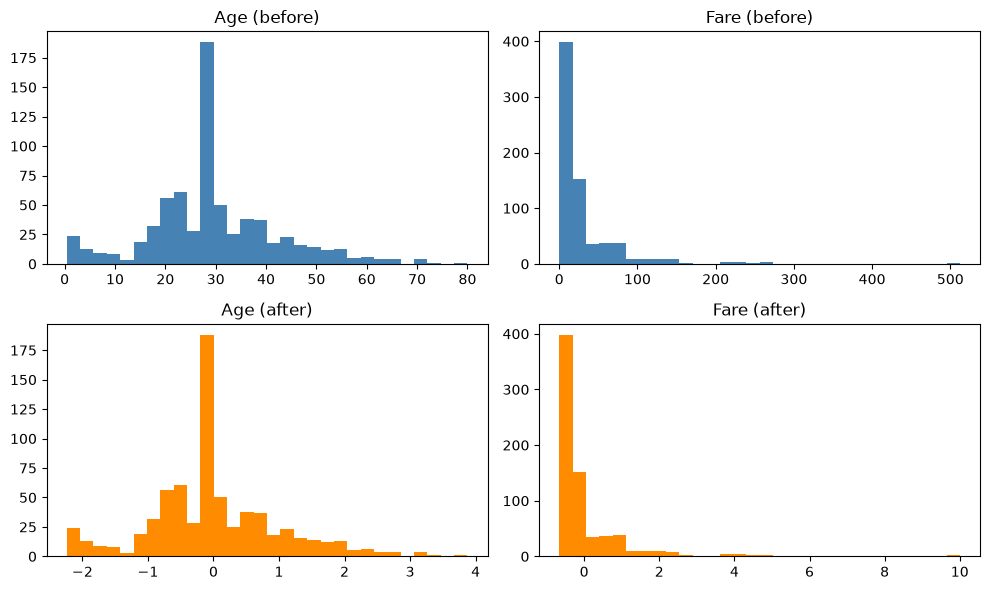

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for i, c in enumerate(['Age', 'Fare']):
    axes[0, i].hist(X_train_enc[c], bins=30, color='steelblue')
    axes[0, i].set_title(f'{c} (before)')
    axes[1, i].hist(X_train_final[c], bins=30, color='darkorange')
    axes[1, i].set_title(f'{c} (after)')
plt.tight_layout()
plt.show()

## 8. Final output

In [11]:
print('X_train:', X_train_final.shape, '| X_test:', X_test_final.shape)
print('y_train:', y_train.shape, '| y_test:', y_test.shape)
print('Missing values:', X_train_final.isna().sum().sum() + X_test_final.isna().sum().sum())
X_train_final.head()

X_train: (712, 18) | X_test: (179, 18)
y_train: (712,) | y_test: (179,)
Missing values: 0


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Deck_U
692,3,0,-0.081135,-0.465084,-0.466183,0.513812,0,0,1,0,0,0,0,0,0,0,0,1
481,2,0,-0.081135,-0.465084,-0.466183,-0.662563,0,0,1,0,0,0,0,0,0,0,0,1
527,1,0,-0.081135,-0.465084,-0.466183,3.955399,0,0,1,0,0,1,0,0,0,0,0,0
855,3,1,-0.887827,-0.465084,0.727782,-0.467874,0,0,1,0,0,0,0,0,0,0,0,1
801,2,1,0.110934,0.478335,0.727782,-0.115977,0,0,1,0,0,0,0,0,0,0,0,1


In [12]:
X_train_final.to_csv('X_train_processed.csv', index=False)
X_test_final.to_csv('X_test_processed.csv', index=False)
y_train.to_csv('y_train.csv', index=False)
y_test.to_csv('y_test.csv', index=False)